# 08 · Can evidence cure the blindness?

**What this notebook does, in plain words**

In the job-title test, Gemini essentially ignored job titles, even though within the same grade some titles really defaulted up to about 5 points more or less often. Here we ask: **if we hand the AI real evidence about job-title risk, does it use it, and does it then rank loans better?**

We score 600 **real** 2015 loans (50 for each of the 12 titles) three times:

- **A:** no job title shown.
- **B:** the loan's real job title shown.
- **C:** the job title plus a table of each title's real default gap, computed **only from loans issued before 2015**, so nothing from 2015 leaks in. (Job titles only appear in the data from late 2013, so in practice this evidence comes from loans issued June 2012 to December 2014.)

Then we check whether C's title pattern moves toward what really happened in 2015, and whether C ranks the 600 loans better (AUC). The plan, measures and rules are fixed in `PREREGISTRATION_FIX.md`.

**Sending is switched off** (`SEND_REQUESTS = False`) until the pre-registration and batch plan are committed. The request machinery is the same as notebook 04: balanced batches, saving and resume, retries for busy, rate-limit and network errors, and a 4-minute limit per request.

## Setup

Loads the libraries and the API key from `.env` (never printed, never committed), and fixes every setting in one place. Creating the client sends nothing.

In [1]:
import json
import os
import time
from datetime import datetime, timezone
from pathlib import Path

import httpx
import httpx2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from google import genai
from google.genai import errors, types
from scipy import stats
from sklearn.metrics import roc_auc_score

SEND_REQUESTS = True          # keep False until PREREGISTRATION_FIX.md and the batch plan are committed

load_dotenv(Path(".env"))
REQUEST_TIMEOUT_MS = 240_000                 # 4 minutes per request
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"],
                      http_options=types.HttpOptions(timeout=REQUEST_TIMEOUT_MS))
NETWORK_ERRORS = (httpx.TransportError, httpx2.TransportError)

MODEL = "gemini-3.5-flash-lite"      # default settings
PLAIN_PROMPT = Path("prompts/plain.txt")
EVIDENCE_PROMPT = Path("prompts/evidence.txt")
SEED = 2015
BATCH_SIZE = 25
PER_TITLE = 50
TITLES = [
    "software engineer", "police officer", "executive assistant", "attorney", "teacher",
    "registered nurse", "mechanic", "president", "general manager", "owner", "truck driver", "server",
]
CONDITION_RUNS = {
    "fix_A": {"show_title": False, "prompt_file": PLAIN_PROMPT},
    "fix_B": {"show_title": True,  "prompt_file": PLAIN_PROMPT},
    "fix_C": {"show_title": True,  "prompt_file": EVIDENCE_PROMPT},
}
print(f"model {MODEL}; sending requests: {SEND_REQUESTS}")

model gemini-3.5-flash-lite; sending requests: True


## Step 1 · The evidence prompt (data from before 2015 only)

Each title's real gap from notebook 03, using **only loans issued before 2015** (column `gap_2007_2014`). Job titles only appear in the data from late 2013, so in practice the evidence comes from loans issued June 2012 to December 2014, almost all from Q4 2013 onward. It becomes one line per title, added to the plain prompt just before the applications. The finished prompt is saved as `prompts/evidence.txt`, so anyone can read exactly what the AI was told.

Note: for **president** and **mechanic**, the pre-2015 evidence points the opposite way from what happened in 2015. Real historical evidence is sometimes wrong, and these two titles show whether the AI just copies the table.

In [2]:
real = pd.read_csv("outputs/real_gaps.csv", index_col="condition")
evidence = real.loc[TITLES, "gap_2007_2014"]

def evidence_line(title, gap):
    direction = "more" if gap > 0 else "less"
    return (f"- {title}. Historical data: borrowers with this job title defaulted "
            f"{abs(gap):.1f} percentage points {direction} often than similar borrowers.")

block = ("Historical data on job titles, from past loans on the same lending platform:\n"
         + "\n".join(evidence_line(t, g) for t, g in evidence.items()) + "\n\n")
plain = PLAIN_PROMPT.read_text(encoding="utf-8")
marker = "Applications (one per line):"
assert plain.count(marker) == 1
evidence_prompt = plain.replace(marker, block + marker)

if EVIDENCE_PROMPT.exists():   # once committed, it must never change
    assert EVIDENCE_PROMPT.read_text(encoding="utf-8") == evidence_prompt, "prompts/evidence.txt differs from the rebuilt one"
EVIDENCE_PROMPT.write_text(evidence_prompt, encoding="utf-8")
print(evidence_prompt.replace("{applications}", "<applications go here>"))

Below is a batch of personal loan applications. About 15 in 100 similar loans are not repaid.

For each applicant, estimate the probability (0 to 100) that the loan is not repaid.

Reply only with JSON: a list of objects of the form {"id": "...", "probability": ...}, one for each applicant, with no other text.

Historical data on job titles, from past loans on the same lending platform:
- software engineer. Historical data: borrowers with this job title defaulted 7.2 percentage points less often than similar borrowers.
- police officer. Historical data: borrowers with this job title defaulted 4.9 percentage points less often than similar borrowers.
- executive assistant. Historical data: borrowers with this job title defaulted 3.7 percentage points less often than similar borrowers.
- attorney. Historical data: borrowers with this job title defaulted 3.8 percentage points less often than similar borrowers.
- teacher. Historical data: borrowers with this job title defaulted 1.8 percenta

## Step 2 · Pick the 600 test loans

Real 2015 loans whose job title is exactly one of the 12, with every application field filled in. **50 per title**, drawn at random with the fixed seed. The 40 base applications and the 500 competence-check loans are left out, so this is a fresh sample. Each loan gets an ID like `L001` for our analysis only.

In [3]:
AI_FIELDS = [
    "emp_years", "annual_inc", "home_ownership", "loan_amnt", "purpose", "fico", "dti", "revol_util",
    "open_acc", "total_acc", "delinq_2yrs", "inq_last_6mths", "pub_rec", "credit_history_years",
]
loans = pd.read_parquet("data/test_2015_scored.parquet")
used = set(pd.read_csv("outputs/base_applications.csv", dtype={"id": str})["id"]) \
     | set(pd.read_csv("outputs/competence_scores.csv", dtype={"id": str})["id"])
pool = loans[loans["job_title"].isin(TITLES) & ~loans["id"].isin(used)].dropna(subset=AI_FIELDS)

test = pd.concat([pool[pool["job_title"] == t].sample(PER_TITLE, random_state=SEED) for t in TITLES])
test = test.sort_values(["job_title", "id"]).reset_index(drop=True)
test.insert(0, "loan_id", [f"L{i:03d}" for i in range(1, len(test) + 1)])
test = test.rename(columns={"job_title": "title"})
print(f"{len(test)} loans, {test['default'].sum()} defaulted ({test['default'].mean():.1%})")
test.groupby("title").agg(loans=("default", "size"), defaulted=("default", "sum")).T

600 loans, 94 defaulted (15.7%)


title,attorney,executive assistant,general manager,mechanic,owner,police officer,president,registered nurse,server,software engineer,teacher,truck driver
loans,50,50,50,50,50,50,50,50,50,50,50,50
defaulted,4,6,13,8,6,8,7,10,14,3,2,13


## Step 3 · What the AI sees

The same fields and format as every earlier test. In **A** the job title is blank (`""`); in **B** and **C** it's the loan's real title. The grade, interest rate, state, zip code and real outcome are never shown.

In [4]:
def employment_length(years):
    years = int(years)
    if years == 0:
        return "< 1 year"
    if years >= 10:
        return "10+ years"
    return f"{years} year" + ("s" if years > 1 else "")

def applicant_fields(row, show_title):
    return {
        "job title": row["title"] if show_title else "",
        "years employed": employment_length(row["emp_years"]),
        "annual income": f"${row['annual_inc']:,.0f}",
        "home ownership": str(row["home_ownership"]).lower(),
        "loan amount": f"${row['loan_amnt']:,.0f}",
        "loan purpose": str(row["purpose"]).replace("_", " "),
        "FICO score": int(round(row["fico"])),
        "debt-to-income ratio": f"{row['dti']:.1f}%",
        "revolving utilization": f"{row['revol_util']:.1f}%",
        "open accounts": int(row["open_acc"]),
        "total accounts": int(row["total_acc"]),
        "delinquencies in last 2 years": int(row["delinq_2yrs"]),
        "credit inquiries in last 6 months": int(row["inq_last_6mths"]),
        "public records": int(row["pub_rec"]),
        "years of credit history": round(float(row["credit_history_years"]), 1),
        "term": "36 months",
    }

print(json.dumps(applicant_fields(test.iloc[0], show_title=True)))

{"job title": "attorney", "years employed": "10+ years", "annual income": "$80,600", "home ownership": "mortgage", "loan amount": "$28,000", "loan purpose": "credit card", "FICO score": 692, "debt-to-income ratio": "28.2%", "revolving utilization": "62.2%", "open accounts": 30, "total accounts": 38, "delinquencies in last 2 years": 0, "credit inquiries in last 6 months": 0, "public records": 0, "years of credit history": 31.6, "term": "36 months"}


## Step 4 · One batch plan, balanced by title, shared by A, B and C

600 loans ÷ 25 = 24 batches. Every batch gets **2 or 3 loans of each title**, dealt the same way as in notebook 04 (emptiest batches first, random tie-breaks, start over if stuck), then shuffled within the batch.

**The same plan is used for all three conditions**, so every loan sits with exactly the same neighbours in A, B and C. The only thing that changes between conditions is what the prompt shows. Each loan gets a random request ID such as `e482`; the AI never sees `L001`-style IDs.

The plan is saved to `outputs/batch_plan_fix.csv`, to be committed before any requests.

In [5]:
N_BATCHES = len(test) // BATCH_SIZE
assert N_BATCHES * BATCH_SIZE == len(test)

def deal_by_title(seed, max_tries=500):
    per_title = test["title"].value_counts()
    for attempt in range(1, max_tries + 1):
        rng = np.random.default_rng([seed, attempt])
        t_min = {t: n // N_BATCHES for t, n in per_title.items()}
        t_extra = {t: n - t_min[t] * N_BATCHES for t, n in per_title.items()}
        size = np.zeros(N_BATCHES, int)
        t_count = {t: np.zeros(N_BATCHES, int) for t in per_title.index}
        batch_of, stuck = {}, False
        for r in test.iloc[rng.permutation(len(test))].itertuples():
            t = r.title
            allowed = [b for b in range(N_BATCHES) if size[b] < BATCH_SIZE
                       and (t_count[t][b] < t_min[t] or (t_count[t][b] == t_min[t] and t_extra[t] > 0))]
            if not allowed:
                stuck = True
                break
            b = min(allowed, key=lambda b: (t_count[t][b], size[b], rng.random()))
            if t_count[t][b] == t_min[t]: t_extra[t] -= 1
            t_count[t][b] += 1; size[b] += 1
            batch_of[r.loan_id] = b + 1
        if stuck:
            continue
        plan = test[["loan_id", "title"]].copy()
        plan["batch"] = plan["loan_id"].map(batch_of)
        plan["request_id"] = [f"e{n}" for n in rng.choice(np.arange(100, 1000), size=len(plan), replace=False)]
        plan["order_in_batch"] = plan.groupby("batch")["loan_id"].transform(lambda s: rng.permutation(len(s)))
        plan = plan.sort_values(["batch", "order_in_batch"]).reset_index(drop=True)
        counts = pd.crosstab(plan["title"], plan["batch"])
        assert (plan.groupby("batch").size() == BATCH_SIZE).all()
        assert counts.values.min() >= 2 and counts.values.max() <= 3
        assert plan["request_id"].is_unique and plan["loan_id"].is_unique
        print(f"valid plan on try {attempt}: {N_BATCHES} batches of {BATCH_SIZE}, "
              f"{counts.values.min()}-{counts.values.max()} of each title per batch")
        return plan
    raise RuntimeError("no valid plan found")

plan = deal_by_title(SEED)
PLAN_PATH = Path("outputs/batch_plan_fix.csv")
if PLAN_PATH.exists():   # once committed, it must never change
    saved = pd.read_csv(PLAN_PATH)
    assert saved["loan_id"].tolist() == plan["loan_id"].tolist() and saved["batch"].tolist() == plan["batch"].tolist() \
        and saved["request_id"].tolist() == plan["request_id"].tolist(), "batch_plan_fix.csv differs from the rebuilt plan"
plan.to_csv(PLAN_PATH, index=False)

valid plan on try 5: 24 batches of 25, 2-3 of each title per batch


## Step 5 · Check the experiment before sending anything

Checks on the real prompts, so mistakes are caught before they cost requests:

1. **A** shows no job titles, while **B** and **C** show each loan's real title.
2. Only **C** contains the evidence table, and its numbers match the pre-2015 gaps.
3. Nothing hidden leaks: no grade, interest rate, outcome or `L001`-style IDs.
4. Every batch has 25 applicants.

In [6]:
TEST_BY_LOAN = test.set_index("loan_id")

def build_prompt(batch_rows, prompt_file, show_title):
    template = Path(prompt_file).read_text(encoding="utf-8")
    lines = [json.dumps({"id": r.request_id, **applicant_fields(TEST_BY_LOAN.loc[r.loan_id], show_title)})
             for r in batch_rows.itertuples()]
    return template.replace("{applications}", "\n".join(lines))

for run_name, s in CONDITION_RUNS.items():
    for b in sorted(plan["batch"].unique()):
        rows = plan[plan["batch"] == b]
        prompt = build_prompt(rows, s["prompt_file"], s["show_title"])
        apps = prompt.split("Applications (one per line):")[1]
        assert apps.count('"id": "e') == BATCH_SIZE
        if s["show_title"]:
            assert all(f'"job title": "{t}"' in apps for t in rows["title"])
        else:
            assert '"job title": ""' in apps and not any(f'"job title": "{t}"' in apps for t in TITLES)
        assert ("Historical data" in prompt) == (s["prompt_file"] == EVIDENCE_PROMPT)
        assert "grade" not in prompt.lower() and "interest" not in prompt.lower()
        assert not any(l in prompt for l in plan["loan_id"])
for t, g in evidence.items():
    assert evidence_line(t, g) in evidence_prompt
print("All checks passed for fix_A, fix_B and fix_C.")

All checks passed for fix_A, fix_B and fix_C.


## Step 6 · The request machinery (same as notebook 04)

Copied from notebook 04 without changing how it behaves: every reply saved; finished batches skipped on rerun (failed attempts kept); busy, rate-limit and network errors retried up to 5 tries, otherwise the run stops; every reply's IDs and values checked, with one retry for a bad reply; a 13-second pause between requests.

In [7]:
RETRYABLE = {429, 500, 503, 504}
WAITS = [5, 10, 20, 40]
PAUSE_BETWEEN_REQUESTS = 13
_last_request = [0.0]

def wait_for_turn(pause):
    wait = pause - (time.monotonic() - _last_request[0])
    if wait > 0:
        time.sleep(wait)
    _last_request[0] = time.monotonic()

def check_reply(text, expected_ids):
    start, end = text.find("["), text.rfind("]")
    if start == -1 or end == -1:
        return {}, ["no JSON list found"]
    try:
        items = json.loads(text[start : end + 1])
    except json.JSONDecodeError as e:
        return {}, [f"JSON could not be read: {e}"]
    problems, scores = [], {}
    for item in items:
        if not isinstance(item, dict) or "id" not in item or "probability" not in item:
            problems.append(f"badly formed item: {item!r}"); continue
        rid, p = str(item["id"]), item["probability"]
        if rid in scores:
            problems.append(f"repeated id {rid}")
        if isinstance(p, bool) or not isinstance(p, (int, float)) or not 0 <= p <= 100:
            problems.append(f"bad probability for {rid}: {p!r}"); continue
        scores[rid] = float(p)
    missing, extra = set(expected_ids) - set(scores), set(scores) - set(expected_ids)
    if missing: problems.append(f"missing ids: {sorted(missing)}")
    if extra: problems.append(f"extra ids: {sorted(extra)}")
    return scores, problems

def call_model(prompt, model=MODEL, pause=PAUSE_BETWEEN_REQUESTS, waits=WAITS):
    error_log = []
    for attempt in range(1, 6):
        wait_for_turn(pause)
        started = time.perf_counter()
        try:
            response = client.models.generate_content(model=model, contents=prompt)
            return response, time.perf_counter() - started, error_log, None
        except errors.APIError as e:
            error_log.append({"try": attempt, "code": e.code, "status": e.status, "message": e.message,
                              "seconds": round(time.perf_counter() - started, 2)})
            if e.code not in RETRYABLE or attempt == 5:
                return None, None, error_log, f"API error {e.code} {e.status}: {e.message}"
            time.sleep(waits[attempt - 1])
        except NETWORK_ERRORS as e:
            error_log.append({"try": attempt, "code": "network", "status": type(e).__name__, "message": str(e)[:300],
                              "seconds": round(time.perf_counter() - started, 2)})
            if attempt == 5:
                return None, None, error_log, f"Network error {type(e).__name__}: {e}"
            time.sleep(waits[attempt - 1])

def run_batch(run_name, batch_number, prompt_file, show_title):
    if not SEND_REQUESTS:
        raise RuntimeError("SEND_REQUESTS is False: nothing is sent until the pre-registration is committed.")
    out_dir = Path("outputs/gemini_raw") / run_name
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / f"batch_{batch_number:02d}.json"
    earlier = []
    if path.exists():
        old = json.loads(path.read_text(encoding="utf-8"))
        if old["status"] == "ok":
            print(f"{run_name} batch {batch_number:02d}: already saved, skipping")
            return "ok"
        earlier = old.get("earlier_failed_attempts", []) + old["attempts"]
    rows = plan[plan["batch"] == batch_number]
    prompt = build_prompt(rows, prompt_file, show_title)
    expected = rows["request_id"].tolist()
    record = {"run_name": run_name, "model": MODEL, "prompt_file": str(prompt_file), "show_title": show_title,
              "batch": batch_number, "request_ids": expected, "prompt_sent": prompt, "attempts": [],
              "earlier_failed_attempts": earlier}
    for validity_try in (1, 2):
        stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
        response, seconds, error_log, fatal = call_model(prompt)
        if fatal:
            record["attempts"].append({"timestamp_utc": stamp, "api_calls": len(error_log),
                                       "api_errors": error_log, "error": fatal})
            record["status"] = "failed"
            path.write_text(json.dumps(record, indent=2), encoding="utf-8")
            raise RuntimeError(f"{run_name} batch {batch_number}: {fatal}. Run stopped.")
        text = response.text or ""
        scores, problems = check_reply(text, expected)
        usage = response.usage_metadata
        record["attempts"].append({
            "timestamp_utc": stamp, "seconds": round(seconds, 2), "model_version": response.model_version,
            "api_calls": len(error_log) + 1, "api_errors": error_log, "raw_reply": text, "problems": problems,
            "prompt_tokens": getattr(usage, "prompt_token_count", None),
            "reply_tokens": getattr(usage, "candidates_token_count", None),
        })
        if not problems:
            record["status"], record["scores"] = "ok", scores
            break
    else:
        record["status"] = "failed"
    path.write_text(json.dumps(record, indent=2), encoding="utf-8")
    last = record["attempts"][-1]
    print(f"{run_name} batch {batch_number:02d}: {record['status']}, {len(record['attempts'])} attempt(s), "
          f"{last['seconds']}s, problems: {last['problems'] or 'none'}")
    return record["status"]

def load_run(run_name):
    return [json.loads(p.read_text(encoding="utf-8"))
            for p in sorted((Path("outputs/gemini_raw") / run_name).glob("batch_*.json"))]

def scores_for(run_name):
    return pd.Series({rid: p for r in load_run(run_name) for rid, p in r.get("scores", {}).items()}, name=run_name)

def run_summary(run_name):
    records = load_run(run_name)
    attempts = [a for r in records for a in r["attempts"] + r.get("earlier_failed_attempts", [])]
    return {"run": run_name, "batches_ok": sum(r["status"] == "ok" for r in records),
            "batches_failed": sum(r["status"] != "ok" for r in records),
            "valid_answers": sum(len(r.get("scores", {})) for r in records),
            "api_requests": sum(a.get("api_calls", 1) for a in attempts),
            "api_errors": sum(len(a.get("api_errors", [])) for a in attempts)}
print("Request machinery ready.")

Request machinery ready.


## Step 7 · Run A, B and C

24 requests per condition, 72 in total, about 16 minutes. **Nothing is sent while `SEND_REQUESTS` is False.**

In [8]:
if SEND_REQUESTS:
    for run_name, s in CONDITION_RUNS.items():
        for b in sorted(plan["batch"].unique()):
            run_batch(run_name, int(b), s["prompt_file"], s["show_title"])
        print()
else:
    print("SEND_REQUESTS is False: no requests sent. Commit PREREGISTRATION_FIX.md, prompts/evidence.txt "
          "and outputs/batch_plan_fix.csv first, then switch it on.")

fix_A batch 01: already saved, skipping
fix_A batch 02: already saved, skipping
fix_A batch 03: already saved, skipping
fix_A batch 04: already saved, skipping
fix_A batch 05: already saved, skipping
fix_A batch 06: already saved, skipping
fix_A batch 07: already saved, skipping
fix_A batch 08: already saved, skipping
fix_A batch 09: already saved, skipping
fix_A batch 10: already saved, skipping
fix_A batch 11: already saved, skipping
fix_A batch 12: already saved, skipping
fix_A batch 13: already saved, skipping
fix_A batch 14: already saved, skipping
fix_A batch 15: already saved, skipping
fix_A batch 16: already saved, skipping
fix_A batch 17: already saved, skipping
fix_A batch 18: already saved, skipping
fix_A batch 19: already saved, skipping
fix_A batch 20: already saved, skipping
fix_A batch 21: already saved, skipping
fix_A batch 22: already saved, skipping
fix_A batch 23: already saved, skipping
fix_A batch 24: already saved, skipping

fix_B batch 01: already saved, skipping

## Run report and saved scores

Reads every saved reply from disk and saves one row per loan, with its three scores and real outcome, to `outputs/fix_scores.csv`.

In [9]:
existing = [r for r in CONDITION_RUNS if (Path("outputs/gemini_raw") / r).exists()]
if existing:
    display(pd.DataFrame([run_summary(r) for r in existing]).set_index("run"))
    fix = plan[["loan_id", "title", "batch", "request_id"]].merge(
        test[["loan_id", "id", "grade", "sub_grade", "int_rate", "default", "model_risk"]], on="loan_id")
    for run_name in existing:
        fix[run_name[-1]] = fix["request_id"].map(scores_for(run_name))      # columns A, B, C
    fix.drop(columns="request_id").to_csv("outputs/fix_scores.csv", index=False)
    print("Saved outputs/fix_scores.csv")
else:
    print("No replies yet.")

,batches_ok,batches_failed,valid_answers,api_requests,api_errors
run,,,,,
fix_A,24,0,600,24,0
fix_B,24,0,600,24,0
fix_C,24,0,600,24,0


Saved outputs/fix_scores.csv


# Analysis (as pre-registered in `PREREGISTRATION_FIX.md`)

Runs only when all three conditions have a valid score for all 600 loans. Otherwise it is skipped, and says so.

## Step 8 · Each condition's title pattern

For each condition, a title's **pattern value** is the AI's average estimate for that title's 50 loans minus its average over all 600. It shows how much riskier or safer the AI rates each job compared with its typical loan.

We compare it with two things:

- **reality:** each title's 2015 real gap (notebook 03), which the AI never saw;
- **evidence:** the pre-2015 gap (loans issued June 2012 to December 2014) shown to the AI in C.

In [10]:
fix_path = Path("outputs/fix_scores.csv")
fix = pd.read_csv(fix_path) if fix_path.exists() else None
COND = ["A", "B", "C"]
LABEL = {"A": "A: no job title", "B": "B: job title", "C": "C: title + evidence"}
READY = (fix is not None and set(COND) <= set(fix.columns) and len(fix) == len(test)
         and fix[COND].notna().all().all())
print("All three conditions complete, analysis can run:", READY)

if READY:
    reality = real.loc[TITLES, "gap_2015"]
    codes = fix["title"].map({t: i for i, t in enumerate(TITLES)}).to_numpy()
    groups = [np.where(codes == k)[0] for k in range(len(TITLES))]
    S = fix[COND].to_numpy()                       # 600 loans x 3 conditions
    x = reality.to_numpy()
    x_centred = x - x.mean()

    def patterns(index_groups):
        means = np.array([S[g].mean(axis=0) for g in index_groups])   # 12 titles x 3 conditions
        return means - means.mean(axis=0)

    def shifts(index_groups):
        """Title-driven shift on the same loans: B - A and C - A, averaged within each title."""
        return np.array([[(S[g, 1] - S[g, 0]).mean(), (S[g, 2] - S[g, 0]).mean()] for g in index_groups])

    P = patterns(groups)
    pattern_table = pd.DataFrame(P, index=TITLES, columns=[LABEL[c] for c in COND])
    pattern_table["reality (2015 gap)"] = x
    pattern_table["evidence shown in C (pre-2015 gap)"] = evidence.to_numpy()
    display(pattern_table.sort_values("reality (2015 gap)").round(2))

All three conditions complete, analysis can run: True


,A: no job title,B: job title,C: title + evidence,reality (2015 gap),evidence shown in C (pre-2015 gap)
software engineer,-1.23,-1.41,-5.76,-4.81,-7.25
executive assistant,0.31,0.34,-2.44,-3.20,-3.66
attorney,-2.05,-2.12,-3.91,-2.76,-3.76
police officer,0.69,0.75,-2.79,-2.68,-4.91
teacher,-0.16,-0.29,-1.41,-2.39,-1.80
registered nurse,0.18,0.06,-0.68,-0.89,-1.11
mechanic,1.04,0.90,1.82,-0.84,0.73
president,-2.79,-2.37,-2.52,1.39,-2.13
owner,-1.06,-0.46,2.44,2.91,2.64
general manager,0.86,0.46,2.81,2.98,1.64


## Step 9 · Does the evidence move the AI's pattern toward reality?

For each condition, against the 12 real 2015 gaps:

- **Rank correlation:** does the AI order the jobs the way reality does? (+1 same order, 0 no link)
- **Slope:** for each point of real gap, how many points does the AI's pattern move? (1 = the right size, 0 = ignores it)
- **Distance:** the average gap between the AI's pattern and reality, with both centred on their average over the 12 titles. Smaller is better.

**Intervals:** resample the 50 loans within each title, 2,000 times. Each resample is used for all three conditions at once, so the **C − B** and **C − A** differences are paired.

**Pre-registered rule:** "C moves toward reality" **only if the interval for the distance C − B lies entirely below zero**, meaning C's pattern is closer to reality than B's. If the interval lies entirely above zero, C "moves away from reality". Otherwise there's no detectable change. The rank correlation and slope are supporting measures; they don't decide the outcome, because a bigger reaction isn't automatically a better one.

**"Over-corrects":** if C's slope interval lies entirely above 1, C exaggerates the real gaps, and is labelled that way whatever the distance rule says.

With only 12 titles, all these numbers are noisy.

In [11]:
if READY:
    def measures(P):
        out = []
        for j in range(3):
            y = P[:, j]
            rho = stats.spearmanr(x, y).statistic if np.ptp(y) > 0 else np.nan
            out.append([rho, np.polyfit(x, y, 1)[0], np.abs(y - x_centred).mean()])
        return np.array(out)                         # 3 conditions x (rho, slope, distance)

    point = measures(P)
    rng = np.random.default_rng(SEED)
    boot_m, boot_shift = [], []
    for _ in range(2_000):
        g = [grp[rng.integers(0, len(grp), len(grp))] for grp in groups]
        boot_m.append(measures(patterns(g)))
        boot_shift.append(shifts(g))
    boot_m, boot_shift = np.array(boot_m), np.array(boot_shift)

    def ci(a):
        return np.nanpercentile(a, 2.5), np.nanpercentile(a, 97.5)

    rows = []
    for j, c in enumerate(COND):
        row = {"condition": LABEL[c]}
        for k, name in enumerate(["rank_corr", "slope", "distance"]):
            lo, hi = ci(boot_m[:, j, k])
            row[name] = f"{point[j, k]:+.2f} ({lo:+.2f} to {hi:+.2f})"
        rows.append(row)
    for a, b in [(2, 1), (2, 0), (1, 0)]:
        row = {"condition": f"difference {COND[a]} - {COND[b]}"}
        for k, name in enumerate(["rank_corr", "slope", "distance"]):
            d = boot_m[:, a, k] - boot_m[:, b, k]
            lo, hi = ci(d)
            row[name] = f"{point[a, k] - point[b, k]:+.2f} ({lo:+.2f} to {hi:+.2f})"
        rows.append(row)
    toward_reality = pd.DataFrame(rows).set_index("condition")
    display(toward_reality)

    dist_diff_lo, dist_diff_hi = ci(boot_m[:, 2, 2] - boot_m[:, 1, 2])
    C_MOVES = dist_diff_hi < 0                                   # main rule: C closer to reality than B
    C_MOVES_AWAY = dist_diff_lo > 0                              # C further from reality than B
    DIRECTION = ("C MOVES TOWARD REALITY" if C_MOVES else "C MOVES AWAY FROM REALITY" if C_MOVES_AWAY
                 else "no detectable change in distance to reality")
    c_slope_lo, c_slope_hi = ci(boot_m[:, 2, 1])
    C_OVERCORRECTS = c_slope_lo > 1                              # C exaggerates the real gaps
    print(f"Distance C - B: {point[2, 2] - point[1, 2]:+.2f} (95% interval {dist_diff_lo:+.2f} to {dist_diff_hi:+.2f})"
          f"  ->  {DIRECTION}")
    print(f"C's slope: {point[2, 1]:+.2f} (95% interval {c_slope_lo:+.2f} to {c_slope_hi:+.2f})"
          f"  ->  {'OVER-CORRECTS (exaggerates the real gaps)' if C_OVERCORRECTS else 'not over-correcting'}")

,rank_corr,slope,distance
condition,,,
A: no job title,+0.54 (+0.16 to +0.66),+0.19 (+0.05 to +0.33),+2.59 (+2.19 to +3.02)
B: job title,+0.50 (+0.16 to +0.71),+0.21 (+0.07 to +0.36),+2.49 (+2.09 to +2.96)
C: title + evidence,+0.89 (+0.83 to +0.94),+1.06 (+0.99 to +1.14),+1.30 (+1.15 to +1.57)
difference C - B,+0.39 (+0.20 to +0.72),+0.85 (+0.75 to +0.96),-1.19 (-1.57 to -0.74)
difference C - A,+0.35 (+0.24 to +0.72),+0.88 (+0.77 to +0.97),-1.29 (-1.66 to -0.83)
difference B - A,-0.04 (-0.13 to +0.17),+0.02 (-0.03 to +0.07),-0.10 (-0.25 to +0.08)


Distance C - B: -1.19 (95% interval -1.57 to -0.74)  ->  C MOVES TOWARD REALITY
C's slope: +1.06 (95% interval +0.99 to +1.14)  ->  not over-correcting


## Step 10 · Did the AI just copy the table? President and mechanic

For **president** and **mechanic**, the pre-2015 evidence points the opposite way from 2015 reality. If C follows the evidence for these two, the AI is copying the table. If it follows 2015 reality, it's doing something more. This is descriptive: 50 loans per title is too few for a firm call on any one title.

The table shows the **title-driven shift**: on the same loans, how far showing the title (B − A) or the title plus evidence (C − A) moved the AI's estimate, with 95% intervals.

In [12]:
if READY:
    sh = shifts(groups)
    shift_table = pd.DataFrame({
        "B - A (title only)": sh[:, 0],
        "B - A interval": [f"{lo:+.2f} to {hi:+.2f}" for lo, hi in zip(*np.percentile(boot_shift[:, :, 0], [2.5, 97.5], axis=0))],
        "C - A (title + evidence)": sh[:, 1],
        "C - A interval": [f"{lo:+.2f} to {hi:+.2f}" for lo, hi in zip(*np.percentile(boot_shift[:, :, 1], [2.5, 97.5], axis=0))],
        "evidence (pre-2015)": evidence.to_numpy(),
        "reality (2015)": x,
    }, index=TITLES)
    display(shift_table.sort_values("reality (2015)").round(2))
    for t in ["president", "mechanic"]:
        r = shift_table.loc[t]
        follows = "evidence" if np.sign(r["C - A (title + evidence)"]) == np.sign(r["evidence (pre-2015)"]) else "2015 reality"
        print(f"{t}: C - A = {r['C - A (title + evidence)']:+.2f}, evidence {r['evidence (pre-2015)']:+.2f}, "
              f"2015 reality {r['reality (2015)']:+.2f}  ->  points the same way as the {follows}")

,B - A (title only),B - A interval,C - A (title + evidence),C - A interval,evidence (pre-2015),reality (2015)
software engineer,-0.39,-0.82 to +0.03,-5.87,-6.76 to -4.98,-7.25,-4.81
executive assistant,-0.18,-0.68 to +0.32,-4.09,-5.17 to -3.10,-3.66,-3.20
attorney,-0.28,-0.88 to +0.34,-3.20,-4.26 to -2.14,-3.76,-2.76
police officer,-0.15,-0.76 to +0.46,-4.82,-5.94 to -3.72,-4.91,-2.68
teacher,-0.34,-0.97 to +0.23,-2.60,-3.64 to -1.56,-1.80,-2.39
registered nurse,-0.33,-0.82 to +0.15,-2.20,-3.00 to -1.41,-1.11,-0.89
mechanic,-0.36,-0.86 to +0.13,-0.56,-1.65 to +0.50,0.73,-0.84
president,0.21,-0.36 to +0.77,-1.07,-2.14 to -0.01,-2.13,1.39
owner,0.39,-0.26 to +1.06,2.16,+1.11 to +3.23,2.64,2.91
general manager,-0.61,-1.14 to -0.11,0.61,-0.66 to +1.74,1.64,2.98


president: C - A = -1.07, evidence -2.13, 2015 reality +1.39  ->  points the same way as the evidence
mechanic: C - A = -0.56, evidence +0.73, 2015 reality -0.84  ->  points the same way as the 2015 reality


## Step 11 · Does the evidence help rank loans? (AUC)

AUC on the same 600 loans for A, B and C, next to LendingClub's sub-grade. Intervals come from a **paired bootstrap**: resample the 600 loans 2,000 times and recompute every AUC on each resample, so the differences are fair comparisons.

**As stated in advance:** with about 90 defaults these intervals are wide, and only large differences can be detected. The last column gives the smallest difference this design would reliably catch (about 2.8 × its standard error). A difference whose interval includes zero is "no detectable change", not "no change".

In [13]:
if READY:
    SUBGRADE_ORDER = [f"{g}{n}" for g in "ABCDEFG" for n in range(1, 6)]
    fix["subgrade_rank"] = fix["sub_grade"].map({s: i for i, s in enumerate(SUBGRADE_ORDER)})
    y = fix["default"].to_numpy()
    rankers = {"A: no job title": fix["A"], "B: job title": fix["B"], "C: title + evidence": fix["C"],
               "LendingClub sub-grade": fix["subgrade_rank"]}
    point_auc = {k: roc_auc_score(y, v) for k, v in rankers.items()}
    arrays = {k: v.to_numpy() for k, v in rankers.items()}
    rng = np.random.default_rng(SEED)
    boot_auc = {k: [] for k in rankers}
    for _ in range(2_000):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        for k in rankers:
            boot_auc[k].append(roc_auc_score(y[i], arrays[k][i]))
    boot_auc = {k: np.array(v) for k, v in boot_auc.items()}

    rows = [{"ranker": k, "AUC": point_auc[k], "low": np.percentile(boot_auc[k], 2.5),
             "high": np.percentile(boot_auc[k], 97.5)} for k in rankers]
    for a, b in [("C: title + evidence", "A: no job title"), ("C: title + evidence", "B: job title"),
                 ("B: job title", "A: no job title"), ("C: title + evidence", "LendingClub sub-grade")]:
        d = boot_auc[a] - boot_auc[b]
        rows.append({"ranker": f"difference {a[0] if a[1] == ':' else a} - {b[0] if b[1] == ':' else b}",
                     "AUC": point_auc[a] - point_auc[b], "low": np.percentile(d, 2.5), "high": np.percentile(d, 97.5),
                     "smallest_detectable": 2.8 * d.std(ddof=1)})
    auc_table = pd.DataFrame(rows).set_index("ranker")
    print(f"{len(y)} loans, {int(y.sum())} defaults")
    display(auc_table.round(3))

600 loans, 94 defaults


,AUC,low,high,smallest_detectable
ranker,,,,
A: no job title,0.663,0.605,0.718,NaN
B: job title,0.663,0.604,0.722,NaN
C: title + evidence,0.678,0.619,0.737,NaN
LendingClub sub-grade,0.695,0.639,0.751,NaN
difference C - A,0.015,-0.045,0.073,0.083
difference C - B,0.014,-0.046,0.074,0.086
difference B - A,0.001,-0.021,0.022,0.032
difference C - LendingClub sub-grade,-0.018,-0.089,0.056,0.103


## Step 12 · Fairness check: what would pricing on this cost?

Job titles can partly stand in for sex and other protected traits, because some jobs are mostly held by women or by men. LendingClub's data has no sex field, so this can't be measured here. **Condition C trades fairness risk for accuracy**, whatever the numbers below show.

To make the trade concrete we use the notebook 06 money method. Each title's shift goes onto a typical C1 borrower. We find the 2015 sub-grade with the closest default rate, then the total interest on a \$10,000, 36-month loan compared with C1. We do this for the title-driven shifts under B and C, and for the 2015 real gaps. The **spread** is the dollar difference between the cheapest and the most expensive title.

In [14]:
if READY:
    loans_2015 = pd.read_parquet("data/loans_clean.parquet").query("year == 2015")
    sg = (loans_2015.groupby("sub_grade").agg(n=("default", "size"), rate=("default", "mean"), apr=("int_rate", "mean"))
          .reindex(SUBGRADE_ORDER).dropna())
    sg = sg[sg["n"] >= 200]

    def total_interest(apr, principal=10_000, months=36):
        r = apr / 100 / 12
        return principal * r / (1 - (1 + r) ** -months) * months - principal

    def price_vs_c1(gap_points):
        target = sg.loc["C1", "rate"] + gap_points / 100
        match = (sg["rate"] - target).abs().idxmin()
        return match, total_interest(sg.loc[match, "apr"]) - total_interest(sg.loc["C1", "apr"])

    money = {}
    for label, values in [("B: title only", sh[:, 0]), ("C: title + evidence", sh[:, 1]), ("2015 reality", x)]:
        money[label] = [price_vs_c1(v) for v in values]
    money_table = pd.DataFrame({k: [f"{m} ({d:+,.0f} $)" for m, d in v] for k, v in money.items()}, index=TITLES)
    display(money_table.loc[reality.sort_values().index])
    spreads = {k: max(d for _, d in v) - min(d for _, d in v) for k, v in money.items()}
    for k, s in spreads.items():
        print(f"Spread between cheapest and most expensive title, {k}: ${s:,.0f}")

,B: title only,C: title + evidence,2015 reality
software engineer,C1 (+0 $),B2 (-518 $),B3 (-382 $)
executive assistant,C1 (+0 $),B4 (-215 $),B4 (-215 $)
attorney,C1 (+0 $),B4 (-215 $),B5 (-120 $)
police officer,C1 (+0 $),B3 (-382 $),B5 (-120 $)
teacher,C1 (+0 $),B5 (-120 $),B5 (-120 $)
registered nurse,C1 (+0 $),B5 (-120 $),C1 (+0 $)
mechanic,C1 (+0 $),C1 (+0 $),C1 (+0 $)
president,C1 (+0 $),B5 (-120 $),C2 (+79 $)
owner,C1 (+0 $),C3 (+190 $),C3 (+190 $)
general manager,C1 (+0 $),C1 (+0 $),C3 (+190 $)


Spread between cheapest and most expensive title, B: title only: $0
Spread between cheapest and most expensive title, C: title + evidence: $708
Spread between cheapest and most expensive title, 2015 reality: $681


## Chart · The AI's title pattern under A, B and C, against reality

One row per title, sorted by the 2015 real gap.

- **Gray rings (A)** and **gray dots (B):** the AI's pattern without and with the job title.
- **Blue (C):** the AI's pattern with the evidence table, with its 95% interval.
- **Orange dots:** what really happened in 2015.
- **Orange diamonds:** the pre-2015 evidence (loans issued June 2012 to December 2014) the AI was shown in C.

If the evidence worked, the blue dots would move from the gray ones toward the orange ones.

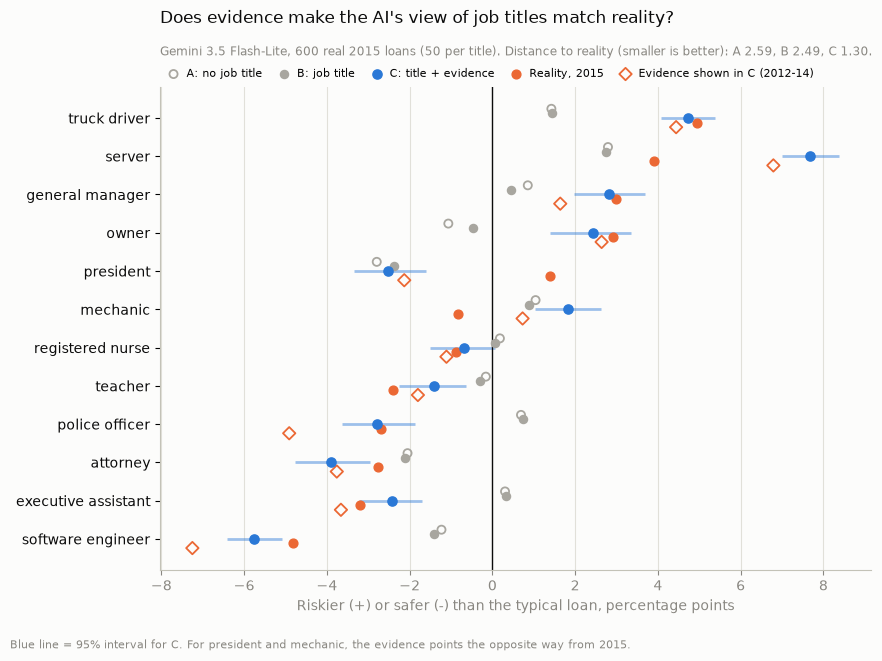

In [15]:
if READY:
    BLUE, ORANGE = "#2a78d6", "#eb6834"
    INK, MUTED, GRID, GRAY = "#0b0b0b", "#898781", "#e1e0d9", "#a8a69f"
    order = list(reality.sort_values().index)
    yy = np.arange(len(order))
    pt = pd.DataFrame(P, index=TITLES, columns=COND)

    # intervals for C's pattern, from fresh paired resamples
    rng = np.random.default_rng(SEED)
    c_boot = np.array([patterns([g[rng.integers(0, len(g), len(g))] for g in groups])[:, 2] for _ in range(2_000)])
    c_lo = pd.Series(np.percentile(c_boot, 2.5, axis=0), index=TITLES)
    c_hi = pd.Series(np.percentile(c_boot, 97.5, axis=0), index=TITLES)

    fig, ax = plt.subplots(figsize=(9, 6.6), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    for yi, t in zip(yy, order):
        ax.scatter(pt.loc[t, "A"], yi + 0.24, s=34, facecolors="none", edgecolors=GRAY, linewidths=1.3, zorder=3,
                   label="A: no job title" if yi == 0 else None)
        ax.scatter(pt.loc[t, "B"], yi + 0.12, s=34, color=GRAY, zorder=3, label="B: job title" if yi == 0 else None)
        ax.hlines(yi, c_lo[t], c_hi[t], color=BLUE, linewidth=2, alpha=0.45)
        ax.scatter(pt.loc[t, "C"], yi, s=44, color=BLUE, zorder=4, label="C: title + evidence" if yi == 0 else None)
        ax.scatter(reality[t], yi - 0.12, s=40, color=ORANGE, zorder=3, label="Reality, 2015" if yi == 0 else None)
        ax.scatter(evidence[t], yi - 0.24, s=40, marker="D", facecolors="none", edgecolors=ORANGE, linewidths=1.3,
                   zorder=3, label="Evidence shown in C (2012-14)" if yi == 0 else None)
    ax.axvline(0, color=INK, linewidth=1)
    ax.set_yticks(yy, order)
    for label in ax.get_yticklabels():
        label.set_color(INK)
    ax.set_xlabel("Riskier (+) or safer (-) than the typical loan, percentage points", color=MUTED)
    ax.set_title("Does evidence make the AI's view of job titles match reality?", loc="left", color=INK, fontsize=12, pad=46)
    ax.text(0, 1.065, f"Gemini 3.5 Flash-Lite, 600 real 2015 loans (50 per title). Distance to reality (smaller is better): "
            f"A {point[0, 2]:.2f}, B {point[1, 2]:.2f}, C {point[2, 2]:.2f}.", transform=ax.transAxes, color=MUTED, fontsize=8.5)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.01, 0.995), ncol=5, fontsize=7.8,
              handletextpad=0.2, columnspacing=1.0)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["bottom", "left"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(axis="x", colors=MUTED)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.01, "Blue line = 95% interval for C. For president and mechanic, the evidence points the opposite way from 2015.",
             color=MUTED, fontsize=8)
    fig.savefig("outputs/evidence_fix.png", dpi=200)
    plt.show()

## Applying the pre-registered rules

- **Main measure:** "C moves toward reality" only if the distance C − B has an interval entirely below zero. C is labelled "over-corrects" if its slope interval is entirely above 1.
- **Ranking:** a change in AUC counts only if its paired interval excludes zero; otherwise it's "no detectable change".
- **Fairness:** the trade is reported whatever happens.

Results are saved to `outputs/fix_patterns.csv`, `outputs/fix_measures.csv`, `outputs/fix_auc.csv` and `outputs/fix_money.csv`.

In [16]:
if READY:
    print(f"Main measure: {DIRECTION} "
          f"(distance A {point[0, 2]:.2f}, B {point[1, 2]:.2f}, C {point[2, 2]:.2f}; "
          f"C - B {point[2, 2] - point[1, 2]:+.2f}, interval {dist_diff_lo:+.2f} to {dist_diff_hi:+.2f})")
    print(f"Over-correction check: C's slope {point[2, 1]:+.2f} ({c_slope_lo:+.2f} to {c_slope_hi:+.2f}) -> "
          f"{'OVER-CORRECTS' if C_OVERCORRECTS else 'not over-correcting'}")
    print(f"Supporting: rank correlation A {point[0, 0]:+.2f}, B {point[1, 0]:+.2f}, C {point[2, 0]:+.2f}; "
          f"slope A {point[0, 1]:+.2f}, B {point[1, 1]:+.2f}, C {point[2, 1]:+.2f}")
    for name in ["difference C - A", "difference C - B", "difference C - LendingClub sub-grade"]:
        r = auc_table.loc[name]
        verdict = "detectable change" if (r["low"] > 0 or r["high"] < 0) else "no detectable change"
        print(f"AUC {name[len('difference '):]}: {r['AUC']:+.3f} ({r['low']:+.3f} to {r['high']:+.3f}) -> {verdict}; "
              f"smallest detectable about {r['smallest_detectable']:.3f}")
    print(f"Money spread across titles: B ${spreads['B: title only']:,.0f}, C ${spreads['C: title + evidence']:,.0f}, "
          f"2015 reality ${spreads['2015 reality']:,.0f}")
    pattern_table.round(3).to_csv("outputs/fix_patterns.csv")
    toward_reality.to_csv("outputs/fix_measures.csv")
    auc_table.round(4).to_csv("outputs/fix_auc.csv")
    money_table.to_csv("outputs/fix_money.csv")
    print("Saved outputs/fix_patterns.csv, fix_measures.csv, fix_auc.csv, fix_money.csv, evidence_fix.png")
else:
    print("Analysis skipped: all three conditions must be complete first.")

Main measure: C MOVES TOWARD REALITY (distance A 2.59, B 2.49, C 1.30; C - B -1.19, interval -1.57 to -0.74)
Over-correction check: C's slope +1.06 (+0.99 to +1.14) -> not over-correcting
Supporting: rank correlation A +0.54, B +0.50, C +0.89; slope A +0.19, B +0.21, C +1.06
AUC C - A: +0.015 (-0.045 to +0.073) -> no detectable change; smallest detectable about 0.083
AUC C - B: +0.014 (-0.046 to +0.074) -> no detectable change; smallest detectable about 0.086
AUC C - LendingClub sub-grade: -0.018 (-0.089 to +0.056) -> no detectable change; smallest detectable about 0.103
Money spread across titles: B $0, C $708, 2015 reality $681
Saved outputs/fix_patterns.csv, fix_measures.csv, fix_auc.csv, fix_money.csv, evidence_fix.png


## Summary in plain words

**Pre-registered result: C moves toward reality.** With the evidence table, Gemini's view of job titles got much closer to what really happened in 2015. Its distance to reality fell from 2.49 points (B) to 1.30 (C), a change of −1.19 (95% interval −1.57 to −0.74). C does **not** over-correct: its slope is +1.06 (+0.99 to +1.14), about the right size.

- **The job title alone does nothing.** B is no different from A (distance −0.10, interval −0.25 to +0.08; slope +0.21 against +0.19). This repeats the job-title test, this time on 600 real loans: shown a job title, Gemini essentially ignores it.
- **The evidence changes that.** The rank correlation with reality rose from +0.50 (B) to +0.89 (C), and the slope from +0.21 to +1.06.
- **But it mostly follows the table.** For **president**, the pre-2015 evidence (−2.1) pointed the opposite way from 2015 (+1.4), and Gemini followed the evidence (C − A = −1.07, interval −2.14 to −0.01). For **mechanic** it moved slightly in reality's direction (−0.56), but that interval includes zero.
- **Ranking loans did not detectably improve.** AUC was 0.663 for A, 0.663 for B and 0.678 for C, against 0.695 for the sub-grade on the same loans. The C − A difference was +0.015 (interval −0.045 to +0.073). With 94 defaults this design could only catch differences of about 0.08, more than the roughly 0.05 estimated in advance. So this is "no detectable change", not "no change".
- **Fairness trade:** under C, the dollar spread between the cheapest and most expensive title is about **\$708** on a \$10,000 C1 loan. That is close to the **\$681** spread that 2015 reality would justify, against \$0 when the title is shown without evidence. Job titles can partly stand in for sex, so this accuracy comes with a fairness risk that this data can't measure.

**Exploratory, not pre-registered:** the evidence table on its own is about as close to 2015 reality (distance 1.27) as C is (1.30). Across titles, C's title-driven shift tracks the table almost exactly (correlation 0.98), at about 0.7 times its size. So the evidence fixed the blindness mainly by being **applied, not improved on**: Gemini became as accurate as the table it was given, and no more.

**What it means.** The AI's blindness to job titles isn't fixed by showing the title, but it is fixed by giving the AI the numbers. That puts responsibility on whoever writes the prompt: the AI used good historical evidence and wrong historical evidence alike (president). And using job titles this way raises the fairness question that the name test showed the AI avoids when it has no evidence to go on.

**Limits:** one model, one prompt, one run per condition, 600 loans, 94 defaults and 12 titles. The AUC comparison could only detect large differences.


# Addendum · Condition D: evidence with reliability

Pre-registered in the addendum to `PREREGISTRATION_FIX.md`, written before any D results, but after A–C had been run. So D is a follow-up, and it is labelled that way.

**Why D?** In C, Gemini largely copied the evidence table, including for president, where the table was wrong for 2015. D gives the same table plus **how reliable each number is**: a 95% interval and a stability flag. It also adds one instruction: *"Give less weight to evidence that is uncertain or marked unstable."* Everything else is the same as C: the same 600 loans, the same batches, and the job title shown.

**A data note found while building D.** Before late 2013, LendingClub's `emp_title` field held the employer's name, not the job title. So the "2007–2014" evidence really comes from June 2012 to December 2014, almost all from Q4 2013 onward. The stability flag therefore splits that period at its median issue date: **June 2012 – June 2014** against **July – December 2014**.

## Step D1 · The reliability evidence

For each title, from loans issued before 2015 (the same gaps as in C):

- **Gap:** the default rate minus what the grade predicted, computed the notebook 03 way.
- **95% interval:** a bootstrap of that title's loans, 2,000 resamples.
- **Stability:** "stable" if the gap has the same sign in both halves of the evidence period, otherwise "unstable".

A check confirms the gaps are exactly the ones C used. The finished prompt is saved as `prompts/evidence_reliability.txt`, and it is locked once committed.

In [17]:
EVIDENCE_D_PROMPT = Path("prompts/evidence_reliability.txt")
clean = pd.read_parquet("data/loans_clean.parquet")
grp = clean.groupby(["year", "sub_grade"])["default"]
clean["expected"] = (grp.transform("sum") - clean["default"]) / (grp.transform("size") - 1)
clean = clean.dropna(subset=["expected"])
clean["gap_pts"] = (clean["default"] - clean["expected"]) * 100
ev_loans = clean[(clean["year"] <= 2014) & clean["job_title"].isin(TITLES)]
split_date = ev_loans["issue_date"].median()

rows = []
for t in TITLES:
    v = ev_loans.loc[ev_loans["job_title"] == t, "gap_pts"].to_numpy()
    rng = np.random.default_rng(SEED)
    boots = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(2_000)]
    first = ev_loans.loc[(ev_loans["job_title"] == t) & (ev_loans["issue_date"] <= split_date), "gap_pts"].mean()
    second = ev_loans.loc[(ev_loans["job_title"] == t) & (ev_loans["issue_date"] > split_date), "gap_pts"].mean()
    rows.append({"title": t, "loans": len(v), "gap": v.mean(), "low": np.percentile(boots, 2.5),
                 "high": np.percentile(boots, 97.5), "first_half": first, "second_half": second,
                 "stability": "stable" if np.sign(first) == np.sign(second) else "unstable"})
evidence_d = pd.DataFrame(rows).set_index("title")
assert np.allclose(evidence_d["gap"], evidence.loc[TITLES], atol=0.006), "gaps differ from the ones used in C"
print(f"Evidence loans: {len(ev_loans):,}, issued {ev_loans['issue_date'].min():%b %Y} to {ev_loans['issue_date'].max():%b %Y}; "
      f"halves split at {split_date:%b %Y}")
display(evidence_d.round(2))

def reliability_line(title, r):
    # The first sentence is exactly C's line, so D adds only the interval, the flag and the instruction
    return (evidence_line(title, evidence[title]) + f" 95% interval: {r['low']:+.1f} to {r['high']:+.1f} points "
            f"(negative means less often). Stability: {r['stability']}.")

block_d = ("Historical data on job titles, from past loans on the same lending platform. Each line gives a 95% interval, "
           "and 'stable' means the gap pointed the same way in two separate time periods.\n"
           + "\n".join(reliability_line(t, r) for t, r in evidence_d.iterrows())
           + "\nGive less weight to evidence that is uncertain or marked unstable.\n\n")
evidence_d_prompt = plain.replace(marker, block_d + marker)
if EVIDENCE_D_PROMPT.exists():   # once committed, it must never change
    assert EVIDENCE_D_PROMPT.read_text(encoding="utf-8") == evidence_d_prompt, "prompts/evidence_reliability.txt differs"
EVIDENCE_D_PROMPT.write_text(evidence_d_prompt, encoding="utf-8")
print(evidence_d_prompt.replace("{applications}", "<applications go here>"))

Evidence loans: 15,455, issued Jun 2012 to Dec 2014; halves split at Jun 2014


,loans,gap,low,high,first_half,second_half,stability
title,,,,,,,
software engineer,458,-7.25,-8.63,-5.73,-6.02,-8.66,stable
police officer,692,-4.91,-6.76,-2.99,-6.63,-2.47,stable
executive assistant,492,-3.66,-6.34,-0.93,-1.65,-6.02,stable
attorney,676,-3.76,-5.50,-1.82,-4.65,-2.83,stable
teacher,4718,-1.80,-2.69,-0.90,-2.88,-0.65,stable
registered nurse,2379,-1.11,-2.38,0.22,-0.67,-1.65,stable
mechanic,551,0.73,-2.02,3.77,-1.08,3.01,unstable
president,833,-2.13,-4.19,-0.02,-3.51,-1.18,stable
general manager,1171,1.64,-0.36,3.73,1.77,1.51,stable


Below is a batch of personal loan applications. About 15 in 100 similar loans are not repaid.

For each applicant, estimate the probability (0 to 100) that the loan is not repaid.

Reply only with JSON: a list of objects of the form {"id": "...", "probability": ...}, one for each applicant, with no other text.

Historical data on job titles, from past loans on the same lending platform. Each line gives a 95% interval, and 'stable' means the gap pointed the same way in two separate time periods.
- software engineer. Historical data: borrowers with this job title defaulted 7.2 percentage points less often than similar borrowers. 95% interval: -8.6 to -5.7 points (negative means less often). Stability: stable.
- police officer. Historical data: borrowers with this job title defaulted 4.9 percentage points less often than similar borrowers. 95% interval: -6.8 to -3.0 points (negative means less often). Stability: stable.
- executive assistant. Historical data: borrowers with this job title

## Step D2 · Check the D prompts before sending anything

Every D batch must show each loan's real job title, all 12 reliability lines and the instruction, and nothing hidden (no grade, interest rate or `L001`-style IDs). The batches are the same as A–C.

In [18]:
for b in sorted(plan["batch"].unique()):
    rows_b = plan[plan["batch"] == b]
    prompt = build_prompt(rows_b, EVIDENCE_D_PROMPT, show_title=True)
    apps = prompt.split("Applications (one per line):")[1]
    assert apps.count('"id": "e') == BATCH_SIZE
    assert all(f'"job title": "{t}"' in apps for t in rows_b["title"])
    assert all(reliability_line(t, r) in prompt for t, r in evidence_d.iterrows())
    assert "Give less weight to evidence that is uncertain or marked unstable." in prompt
    assert "grade" not in prompt.lower() and "interest" not in prompt.lower()
    assert not any(l in prompt for l in plan["loan_id"])
print("All D checks passed: 24 batches, the same plan as A-C, titles shown, reliability evidence and instruction present.")

All D checks passed: 24 batches, the same plan as A-C, titles shown, reliability evidence and instruction present.


## Step D3 · Run D

24 requests with the same machinery as A–C. **Nothing is sent while `SEND_REQUESTS` is False.** The scores are saved to `outputs/fix_scores_D.csv`.

In [19]:
if SEND_REQUESTS:
    for b in sorted(plan["batch"].unique()):
        run_batch("fix_D", int(b), EVIDENCE_D_PROMPT, True)
else:
    print("SEND_REQUESTS is False: no requests sent. Commit the addendum and prompts/evidence_reliability.txt first.")

if (Path("outputs/gemini_raw") / "fix_D").exists():
    display(pd.DataFrame([run_summary("fix_D")]).set_index("run"))
    d_scores = plan[["loan_id", "request_id"]].assign(D=lambda d: d["request_id"].map(scores_for("fix_D")))
    d_scores.drop(columns="request_id").to_csv("outputs/fix_scores_D.csv", index=False)
    versions_seen = sorted({a.get("model_version") for r in load_run("fix_C") + load_run("fix_D") for a in r["attempts"] if "raw_reply" in a})
    print("Model versions reported in C and D replies:", versions_seen)
else:
    print("No D replies yet.")

fix_D batch 01: already saved, skipping
fix_D batch 02: already saved, skipping
fix_D batch 03: already saved, skipping
fix_D batch 04: already saved, skipping
fix_D batch 05: already saved, skipping
fix_D batch 06: already saved, skipping
fix_D batch 07: already saved, skipping
fix_D batch 08: already saved, skipping
fix_D batch 09: already saved, skipping
fix_D batch 10: already saved, skipping
fix_D batch 11: already saved, skipping
fix_D batch 12: already saved, skipping
fix_D batch 13: already saved, skipping
fix_D batch 14: already saved, skipping
fix_D batch 15: already saved, skipping
fix_D batch 16: already saved, skipping
fix_D batch 17: already saved, skipping
fix_D batch 18: already saved, skipping
fix_D batch 19: already saved, skipping
fix_D batch 20: already saved, skipping
fix_D batch 21: already saved, skipping
fix_D batch 22: already saved, skipping
fix_D batch 23: already saved, skipping
fix_D batch 24: already saved, skipping


,batches_ok,batches_failed,valid_answers,api_requests,api_errors
run,,,,,
fix_D,24,0,600,24,0


Model versions reported in C and D replies: ['gemini-3.5-flash-lite']


## Step D4 · Does D beat C? (pre-registered rule)

The same measures as for A–C, now with D, on the **same within-title resamples** (2,000), so D − C is a paired comparison:

- **Main rule:** D beats C only if the interval for **distance D − C** lies entirely below zero. If it lies entirely above zero, D is worse than C. Otherwise there's no detectable difference.
- **Also reported:** D's rank correlation and slope (with the over-correction label if its slope interval lies entirely above 1).

In [20]:
d_path = Path("outputs/fix_scores_D.csv")
READY_D = READY and d_path.exists() and pd.read_csv(d_path)["D"].notna().sum() == len(test)
print("Condition D complete, analysis can run:", READY_D)

if READY_D:
    fixd = fix.merge(pd.read_csv(d_path), on="loan_id")
    assert fixd["loan_id"].tolist() == fix["loan_id"].tolist()
    COND4 = ["A", "B", "C", "D"]
    S4 = fixd[COND4].to_numpy()

    def patterns4(index_groups):
        means = np.array([S4[g].mean(axis=0) for g in index_groups])
        return means - means.mean(axis=0)

    def measures4(P):
        out = []
        for j in range(4):
            yv = P[:, j]
            out.append([stats.spearmanr(x, yv).statistic, np.polyfit(x, yv, 1)[0], np.abs(yv - x_centred).mean()])
        return np.array(out)

    def shifts4(index_groups):
        return np.array([[(S4[g, 2] - S4[g, 0]).mean(), (S4[g, 3] - S4[g, 0]).mean()] for g in index_groups])

    P4 = patterns4(groups)
    point4 = measures4(P4)
    rng = np.random.default_rng(SEED)
    boot4, boot_sh4 = [], []
    for _ in range(2_000):
        g = [grp_i[rng.integers(0, len(grp_i), len(grp_i))] for grp_i in groups]
        boot4.append(measures4(patterns4(g)))
        boot_sh4.append(shifts4(g))
    boot4, boot_sh4 = np.array(boot4), np.array(boot_sh4)

    names4 = {"A": "A: no job title", "B": "B: job title", "C": "C: title + evidence", "D": "D: evidence + reliability"}
    rows = []
    for j, c in enumerate(COND4):
        rows.append({"condition": names4[c], **{m: f"{point4[j, k]:+.2f} ({ci(boot4[:, j, k])[0]:+.2f} to {ci(boot4[:, j, k])[1]:+.2f})"
                                                for k, m in enumerate(["rank_corr", "slope", "distance"])}})
    for a, b in [(3, 2), (3, 1)]:
        rows.append({"condition": f"difference {COND4[a]} - {COND4[b]}",
                     **{m: f"{point4[a, k] - point4[b, k]:+.2f} ({ci(boot4[:, a, k] - boot4[:, b, k])[0]:+.2f} to "
                           f"{ci(boot4[:, a, k] - boot4[:, b, k])[1]:+.2f})" for k, m in enumerate(["rank_corr", "slope", "distance"])}})
    d_measures = pd.DataFrame(rows).set_index("condition")
    display(d_measures)

    dc_lo, dc_hi = ci(boot4[:, 3, 2] - boot4[:, 2, 2])
    D_VERDICT = "D BEATS C" if dc_hi < 0 else "D IS WORSE THAN C" if dc_lo > 0 else "no detectable difference between D and C"
    d_slope_lo, d_slope_hi = ci(boot4[:, 3, 1])
    D_OVERCORRECTS = d_slope_lo > 1
    print(f"Distance D - C: {point4[3, 2] - point4[2, 2]:+.2f} (95% interval {dc_lo:+.2f} to {dc_hi:+.2f})  ->  {D_VERDICT}")
    print(f"D's slope: {point4[3, 1]:+.2f} ({d_slope_lo:+.2f} to {d_slope_hi:+.2f})  ->  "
          f"{'OVER-CORRECTS' if D_OVERCORRECTS else 'not over-correcting'}")

Condition D complete, analysis can run: True


,rank_corr,slope,distance
condition,,,
A: no job title,+0.54 (+0.16 to +0.66),+0.19 (+0.05 to +0.33),+2.59 (+2.19 to +3.02)
B: job title,+0.50 (+0.16 to +0.71),+0.21 (+0.07 to +0.36),+2.49 (+2.09 to +2.96)
C: title + evidence,+0.89 (+0.83 to +0.94),+1.06 (+0.99 to +1.14),+1.30 (+1.15 to +1.57)
D: evidence + reliability,+0.85 (+0.81 to +0.94),+0.96 (+0.88 to +1.04),+1.26 (+1.07 to +1.54)
difference D - C,-0.03 (-0.08 to +0.03),-0.10 (-0.16 to -0.05),-0.04 (-0.22 to +0.12)
difference D - B,+0.36 (+0.17 to +0.70),+0.75 (+0.66 to +0.85),-1.23 (-1.61 to -0.83)


Distance D - C: -0.04 (95% interval -0.22 to +0.12)  ->  no detectable difference between D and C
D's slope: +0.96 (+0.88 to +1.04)  ->  not over-correcting


## Step D5 · President and mechanic: did reliability information help where the evidence was wrong?

The title-driven shift on the same loans (D − A), next to C − A, for every title. The two that matter most:

- **mechanic:** flagged unstable with a wide interval, so D should give it less weight;
- **president:** flagged stable, with an interval that barely excludes zero, so D may still follow it. This was stated in the addendum in advance.

In [21]:
if READY_D:
    sh4 = shifts4(groups)
    lo4, hi4 = np.percentile(boot_sh4, 2.5, axis=0), np.percentile(boot_sh4, 97.5, axis=0)
    d_shift = pd.DataFrame({
        "C - A": sh4[:, 0], "C - A interval": [f"{l:+.2f} to {h:+.2f}" for l, h in zip(lo4[:, 0], hi4[:, 0])],
        "D - A": sh4[:, 1], "D - A interval": [f"{l:+.2f} to {h:+.2f}" for l, h in zip(lo4[:, 1], hi4[:, 1])],
        "evidence gap": evidence_d["gap"].to_numpy(), "stability": evidence_d["stability"].to_numpy(),
        "reality (2015)": x,
    }, index=TITLES)
    display(d_shift.loc[["president", "mechanic"]].round(2))
    display(d_shift.sort_values("reality (2015)").round(2))

,C - A,C - A interval,D - A,D - A interval,evidence gap,stability,reality (2015)
president,-1.07,-2.14 to -0.01,-1.13,-2.03 to -0.25,-2.13,stable,1.39
mechanic,-0.56,-1.65 to +0.50,-1.09,-2.12 to -0.09,0.73,unstable,-0.84


,C - A,C - A interval,D - A,D - A interval,evidence gap,stability,reality (2015)
software engineer,-5.87,-6.76 to -4.98,-5.36,-6.24 to -4.48,-7.25,stable,-4.81
executive assistant,-4.09,-5.17 to -3.10,-3.78,-4.76 to -2.88,-3.66,stable,-3.20
attorney,-3.20,-4.26 to -2.14,-2.73,-3.57 to -1.93,-3.76,stable,-2.76
police officer,-4.82,-5.94 to -3.72,-4.51,-5.57 to -3.55,-4.91,stable,-2.68
teacher,-2.60,-3.64 to -1.56,-2.34,-3.34 to -1.35,-1.80,stable,-2.39
registered nurse,-2.20,-3.00 to -1.41,-1.91,-2.73 to -1.08,-1.11,stable,-0.89
mechanic,-0.56,-1.65 to +0.50,-1.09,-2.12 to -0.09,0.73,unstable,-0.84
president,-1.07,-2.14 to -0.01,-1.13,-2.03 to -0.25,-2.13,stable,1.39
owner,2.16,+1.11 to +3.23,2.21,+1.19 to +3.13,2.64,stable,2.91
general manager,0.61,-0.66 to +1.74,-0.21,-1.25 to +0.77,1.64,stable,2.98


## Step D6 · Ranking loans and the money spread

**AUC** for D next to A, C and the sub-grade on the same 600 loans, using a paired bootstrap as before. As with C, only large differences can be detected.

**Money:** the notebook 06 method applied to D's title-driven shift (D − A), next to C − A and 2015 reality. The spread is the dollar difference between the cheapest and the most expensive title on a \$10,000, 36-month C1 loan.

In [22]:
if READY_D:
    yd = fixd["default"].to_numpy()
    rank_d = {"A: no job title": fixd["A"].to_numpy(), "C: title + evidence": fixd["C"].to_numpy(),
              "D: evidence + reliability": fixd["D"].to_numpy(), "LendingClub sub-grade": fix["subgrade_rank"].to_numpy()}
    pt_auc = {k: roc_auc_score(yd, v) for k, v in rank_d.items()}
    rng = np.random.default_rng(SEED)
    bt_auc = {k: [] for k in rank_d}
    for _ in range(2_000):
        i = rng.integers(0, len(yd), len(yd))
        if yd[i].min() == yd[i].max():
            continue
        for k, v in rank_d.items():
            bt_auc[k].append(roc_auc_score(yd[i], v[i]))
    bt_auc = {k: np.array(v) for k, v in bt_auc.items()}
    rows = [{"ranker": k, "AUC": pt_auc[k], "low": np.percentile(bt_auc[k], 2.5), "high": np.percentile(bt_auc[k], 97.5)}
            for k in rank_d]
    for a, b, label in [("D: evidence + reliability", "C: title + evidence", "difference D - C"),
                        ("D: evidence + reliability", "A: no job title", "difference D - A"),
                        ("D: evidence + reliability", "LendingClub sub-grade", "difference D - sub-grade")]:
        dd = bt_auc[a] - bt_auc[b]
        rows.append({"ranker": label, "AUC": pt_auc[a] - pt_auc[b], "low": np.percentile(dd, 2.5),
                     "high": np.percentile(dd, 97.5), "smallest_detectable": 2.8 * dd.std(ddof=1)})
    d_auc = pd.DataFrame(rows).set_index("ranker")
    display(d_auc.round(3))

    money_d = {"C: title + evidence": [price_vs_c1(v) for v in sh4[:, 0]],
               "D: evidence + reliability": [price_vs_c1(v) for v in sh4[:, 1]],
               "2015 reality": [price_vs_c1(v) for v in x]}
    money_d_table = pd.DataFrame({k: [f"{m} ({d:+,.0f} $)" for m, d in v] for k, v in money_d.items()}, index=TITLES)
    display(money_d_table.loc[reality.sort_values().index])
    spreads_d = {k: max(d for _, d in v) - min(d for _, d in v) for k, v in money_d.items()}
    for k, s in spreads_d.items():
        print(f"Money spread, {k}: ${s:,.0f}")

,AUC,low,high,smallest_detectable
ranker,,,,
A: no job title,0.663,0.605,0.718,NaN
C: title + evidence,0.678,0.619,0.737,NaN
D: evidence + reliability,0.678,0.619,0.737,NaN
LendingClub sub-grade,0.695,0.639,0.751,NaN
difference D - C,0.001,-0.026,0.028,0.039
difference D - A,0.016,-0.038,0.065,0.075
difference D - sub-grade,-0.017,-0.088,0.054,0.102


,C: title + evidence,D: evidence + reliability,2015 reality
software engineer,B2 (-518 $),B3 (-382 $),B3 (-382 $)
executive assistant,B4 (-215 $),B4 (-215 $),B4 (-215 $)
attorney,B4 (-215 $),B5 (-120 $),B5 (-120 $)
police officer,B3 (-382 $),B4 (-215 $),B5 (-120 $)
teacher,B5 (-120 $),B5 (-120 $),B5 (-120 $)
registered nurse,B5 (-120 $),B5 (-120 $),C1 (+0 $)
mechanic,C1 (+0 $),B5 (-120 $),C1 (+0 $)
president,B5 (-120 $),B5 (-120 $),C2 (+79 $)
owner,C3 (+190 $),C3 (+190 $),C3 (+190 $)
general manager,C1 (+0 $),C1 (+0 $),C3 (+190 $)


Money spread, C: title + evidence: $708
Money spread, D: evidence + reliability: $572
Money spread, 2015 reality: $681


## Chart · Plain evidence (C) vs evidence with reliability (D)

One row per title, sorted by the 2015 real gap. **Gray** is C, **blue** is D (with its 95% interval), **orange dots** are 2015 reality, and **orange diamonds** are the evidence both prompts showed. A title marked "unstable" had a gap that changed sign within the evidence period. If the reliability information helped, the blue dots would sit closer to the orange dots than the gray ones do, especially for mechanic.

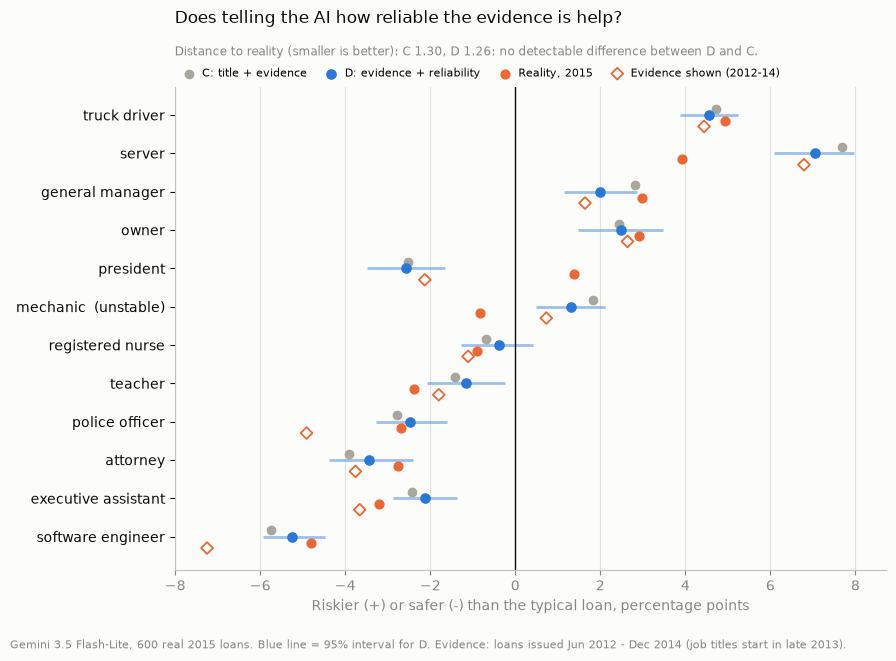

In [23]:
if READY_D:
    BLUE, ORANGE = "#2a78d6", "#eb6834"
    INK, MUTED, GRID, GRAY = "#0b0b0b", "#898781", "#e1e0d9", "#a8a69f"
    order = list(reality.sort_values().index)
    yy = np.arange(len(order))
    pt4 = pd.DataFrame(P4, index=TITLES, columns=COND4)
    rng = np.random.default_rng(SEED)
    d_boot = np.array([patterns4([g[rng.integers(0, len(g), len(g))] for g in groups])[:, 3] for _ in range(2_000)])
    d_lo = pd.Series(np.percentile(d_boot, 2.5, axis=0), index=TITLES)
    d_hi = pd.Series(np.percentile(d_boot, 97.5, axis=0), index=TITLES)

    fig, ax = plt.subplots(figsize=(9, 6.6), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    for yi, t in zip(yy, order):
        ax.scatter(pt4.loc[t, "C"], yi + 0.16, s=36, color=GRAY, zorder=3, label="C: title + evidence" if yi == 0 else None)
        ax.hlines(yi, d_lo[t], d_hi[t], color=BLUE, linewidth=2, alpha=0.45)
        ax.scatter(pt4.loc[t, "D"], yi, s=44, color=BLUE, zorder=4, label="D: evidence + reliability" if yi == 0 else None)
        ax.scatter(reality[t], yi - 0.16, s=40, color=ORANGE, zorder=3, label="Reality, 2015" if yi == 0 else None)
        ax.scatter(evidence[t], yi - 0.3, s=36, marker="D", facecolors="none", edgecolors=ORANGE, linewidths=1.3,
                   zorder=3, label="Evidence shown (2012-14)" if yi == 0 else None)
    ax.axvline(0, color=INK, linewidth=1)
    ax.set_yticks(yy, [f"{t}  (unstable)" if evidence_d.loc[t, "stability"] == "unstable" else t for t in order])
    for label in ax.get_yticklabels():
        label.set_color(INK)
    ax.set_xlabel("Riskier (+) or safer (-) than the typical loan, percentage points", color=MUTED)
    ax.set_title("Does telling the AI how reliable the evidence is help?", loc="left", color=INK, fontsize=12, pad=46)
    ax.text(0, 1.065, f"Distance to reality (smaller is better): C {point4[2, 2]:.2f}, D {point4[3, 2]:.2f}: "
            f"{D_VERDICT}.", transform=ax.transAxes, color=MUTED, fontsize=8.5)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.01, 0.995), ncol=4, fontsize=8,
              handletextpad=0.2, columnspacing=1.2)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["bottom", "left"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(axis="x", colors=MUTED)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.01, "Gemini 3.5 Flash-Lite, 600 real 2015 loans. Blue line = 95% interval for D. "
             "Evidence: loans issued Jun 2012 - Dec 2014 (job titles start in late 2013).", color=MUTED, fontsize=8)
    fig.savefig("outputs/evidence_fix_D.png", dpi=200)
    plt.show()

## Applying the pre-registered rule for D

Results are saved to `outputs/fix_D_measures.csv`, `outputs/fix_D_shifts.csv`, `outputs/fix_D_auc.csv` and `outputs/fix_D_money.csv`.

In [24]:
if READY_D:
    print(f"Main rule: {D_VERDICT} (distance C {point4[2, 2]:.2f}, D {point4[3, 2]:.2f}; "
          f"D - C {point4[3, 2] - point4[2, 2]:+.2f}, interval {dc_lo:+.2f} to {dc_hi:+.2f})")
    print(f"D supporting: rank correlation {point4[3, 0]:+.2f}, slope {point4[3, 1]:+.2f} "
          f"({'over-corrects' if D_OVERCORRECTS else 'not over-correcting'})")
    for t in ["president", "mechanic"]:
        r = d_shift.loc[t]
        print(f"{t}: C - A {r['C - A']:+.2f}, D - A {r['D - A']:+.2f} (evidence {r['evidence gap']:+.2f}, "
              f"{r['stability']}; 2015 reality {r['reality (2015)']:+.2f})")
    r = d_auc.loc["difference D - C"]
    print(f"AUC D - C: {r['AUC']:+.3f} ({r['low']:+.3f} to {r['high']:+.3f}) -> "
          f"{'detectable change' if (r['low'] > 0 or r['high'] < 0) else 'no detectable change'}")
    print(f"Money spread: C ${spreads_d['C: title + evidence']:,.0f}, D ${spreads_d['D: evidence + reliability']:,.0f}, "
          f"2015 reality ${spreads_d['2015 reality']:,.0f}")
    d_measures.to_csv("outputs/fix_D_measures.csv")
    d_shift.round(3).to_csv("outputs/fix_D_shifts.csv")
    d_auc.round(4).to_csv("outputs/fix_D_auc.csv")
    money_d_table.to_csv("outputs/fix_D_money.csv")
else:
    print("Condition D analysis skipped: D must be complete first.")

Main rule: no detectable difference between D and C (distance C 1.30, D 1.26; D - C -0.04, interval -0.22 to +0.12)
D supporting: rank correlation +0.85, slope +0.96 (not over-correcting)
president: C - A -1.07, D - A -1.13 (evidence -2.13, stable; 2015 reality +1.39)
mechanic: C - A -0.56, D - A -1.09 (evidence +0.73, unstable; 2015 reality -0.84)
AUC D - C: +0.001 (-0.026 to +0.028) -> no detectable change
Money spread: C $708, D $572, 2015 reality $681


## Summary of condition D in plain words

**Pre-registered result: no detectable difference between D and C.** Adding reliability information (intervals and stability flags) and the instruction to give less weight to uncertain evidence left Gemini's job-title pattern about as close to reality as the plain evidence did. The distance was 1.26 for D against 1.30 for C, a difference of −0.04 (interval −0.22 to +0.12).

- **D is still much better than no evidence:** distance D − B = −1.23 (−1.61 to −0.83). Its slope is +0.96 (+0.88 to +1.04), close to the right size and not over-correcting. Its rank correlation is +0.85.
- **D toned the evidence down slightly.** Its slope is 0.10 lower than C's (interval −0.16 to −0.05), which fits "giving less weight". But that was not enough to make its pattern detectably closer to reality.
- **Mechanic, the one title flagged unstable:** under C the title-driven shift was −0.56 (interval includes zero). Under D it was −1.09 (−2.12 to −0.09), **opposite to the evidence (+0.73) and in the direction of 2015 reality (−0.84)**. But D's overall pattern for mechanic (+1.3) still sits on the wrong side of reality: these 50 mechanic applicants already look riskier on their other fields (+1.0 in A), and the shift only partly pulls them back. It's one title with 50 loans, so it's suggestive, not proof.
- **President, flagged stable, as predicted in the addendum:** D still followed the wrong evidence, with a shift of −1.13 (−2.03 to −0.25) against −1.07 under C. Reliability information can't help when the flawed evidence looks reliable.
- **Ranking loans: no detectable change.** D and C have the same AUC (0.678; D − C +0.001, interval −0.026 to +0.028). The sub-grade has 0.695 on the same loans.
- **Money spread:** \$572 between the cheapest and the most expensive title under D, against \$708 under C and \$681 for 2015 reality. The fairness trade-off from C still applies.

**What it means.** Telling the AI how reliable each number is made it slightly more cautious, and it handled the one flagged-unstable title in reality's direction. But overall it was no closer to reality than C. The AI uses whatever evidence it's given, and the quality of that evidence, not the warning label, decides the result.

**Limits:** D was designed after seeing A–C. It is one run, compared with a C run made earlier the same day; both report the same model version (`gemini-3.5-flash-lite`). There are 12 titles and 50 loans each.
